# Projet 18 — Détection de fraude par carte bancaire

Ce notebook présente un projet simple de Data Mining pour détecter des transactions frauduleuses dans un dataset très déséquilibré.

**Dataset attendu :** Credit Card Fraud Detection depuis Kaggle. Le fichier doit s'appeler `creditcard.csv` et être placé dans le même dossier que ce notebook.

**Objectif :** comparer plusieurs modèles pour repérer les fraudes rares, puis interpréter les résultats avec des métriques adaptées.

## 1. 01_import_libraries

On importe les bibliothèques nécessaires : manipulation des données, visualisation, prétraitement, modèles et métriques d'évaluation.

In [30]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Prétraitement et séparation des données
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Modèles
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest

# Métriques d'évaluation
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Paramètres généraux pour rendre les résultats reproductibles
RANDOM_STATE = 42

# Style des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 14

## 2. 02_load_dataset

On charge le fichier `creditcard.csv` avec un chemin relatif. Cela permet au notebook de fonctionner facilement si le CSV est placé à côté du notebook.

In [31]:
DATA_PATH = "creditcard.csv"

df = pd.read_csv(DATA_PATH)

print("Dimensions du dataset :", df.shape)
df.head()

Dimensions du dataset : (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. 03_problem_understanding

Le problème est une **classification binaire** :

- `Class = 0` : transaction normale
- `Class = 1` : transaction frauduleuse

Dans ce projet, les fraudes sont rares. Le dataset est donc très déséquilibré. Cela signifie qu'un modèle peut avoir une très bonne accuracy simplement en prédisant presque toujours "non fraude".

Pour cette raison, l'accuracy ne sera pas utilisée comme métrique principale. On préfère regarder :

- le **recall**, pour mesurer la capacité à retrouver les fraudes ;
- la **precision**, pour mesurer la qualité des alertes ;
- le **F1-score**, compromis entre precision et recall ;
- le **ROC-AUC** et le **PR-AUC**, utiles pour comparer les scores de modèles.

In [32]:
# Identification explicite de la cible
TARGET = "Class"

# Nombre de transactions normales et frauduleuses
class_counts = df[TARGET].value_counts().sort_index()
normal_count = class_counts.get(0, 0)
fraud_count = class_counts.get(1, 0)
total_count = len(df)
fraud_percentage = fraud_count / total_count * 100

print(f"Nombre de transactions normales : {normal_count}")
print(f"Nombre de fraudes : {fraud_count}")
print(f"Pourcentage de fraudes : {fraud_percentage:.4f}%")

Nombre de transactions normales : 284315
Nombre de fraudes : 492
Pourcentage de fraudes : 0.1727%


## 4. 04_dataset_description

Le dataset contient :

- `Time` : temps écoulé depuis la première transaction du dataset ;
- `Amount` : montant de la transaction ;
- `V1` à `V28` : variables numériques transformées, issues d'une PCA ;
- `Class` : variable cible.

On vérifie maintenant les colonnes, les types et quelques statistiques descriptives.

In [33]:
# Liste des colonnes attendues
expected_columns = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]

print("Nombre de colonnes :", len(df.columns))
print("Colonnes présentes :")
print(df.columns.tolist())

missing_expected = [col for col in expected_columns if col not in df.columns]
if missing_expected:
    print("Colonnes attendues manquantes :", missing_expected)
else:
    print("Toutes les colonnes attendues sont présentes.")

Nombre de colonnes : 31
Colonnes présentes :
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Toutes les colonnes attendues sont présentes.


In [34]:
# Informations générales sur le dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [35]:
# Statistiques descriptives des colonnes principales
df[["Time", "Amount", "Class"]].describe()

,Time,Amount,Class
count,284807.000000,284807.000000,284807.000000
mean,94813.859575,88.349619,0.001727
std,47488.145955,250.120109,0.041527
min,0.000000,0.000000,0.000000
25%,54201.500000,5.600000,0.000000
50%,84692.000000,22.000000,0.000000
75%,139320.500000,77.165000,0.000000
max,172792.000000,25691.160000,1.000000


In [36]:
# Statistiques descriptives des variables V1 à V28
v_columns = [f"V{i}" for i in range(1, 29)]
df[v_columns].describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995
V10,284807.0,2.239053e-15,1.088850,-24.588262,-0.535426,-0.092917,0.453923,23.745136


## 5. 05_exploratory_data_analysis

L'analyse exploratoire permet de mieux comprendre les données avant la modélisation.

C:\Users\YASSINE\AppData\Local\Temp\ipykernel_12788\1374430879.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Class", palette=["#4C78A8", "#E45756"])


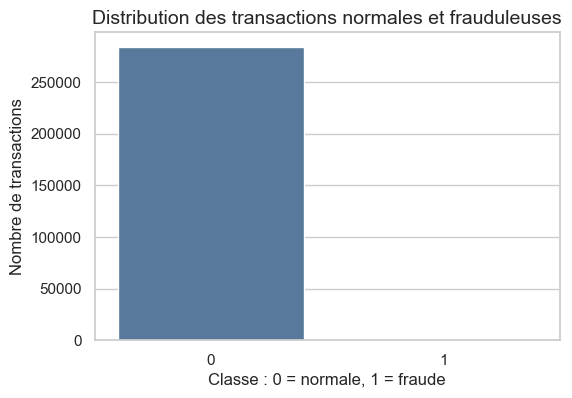

Répartition en pourcentage :
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


In [ ]:
# Distribution de la variable cible Class
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Class", palette=["#4C78A8", "#E45756"])
plt.title("Distribution des transactions normales et frauduleuses")
plt.xlabel("Classe : 0 = normale, 1 = fraude")
plt.ylabel("Nombre de transactions")
plt.show()

print("Répartition en pourcentage :")
print((df["Class"].value_counts(normalize=True).sort_index() * 100).round(4))

**Interprétation :** ce graphique montre que les transactions frauduleuses représentent une très petite partie du dataset. Le problème est donc fortement déséquilibré, ce qui rend l'accuracy peu fiable.

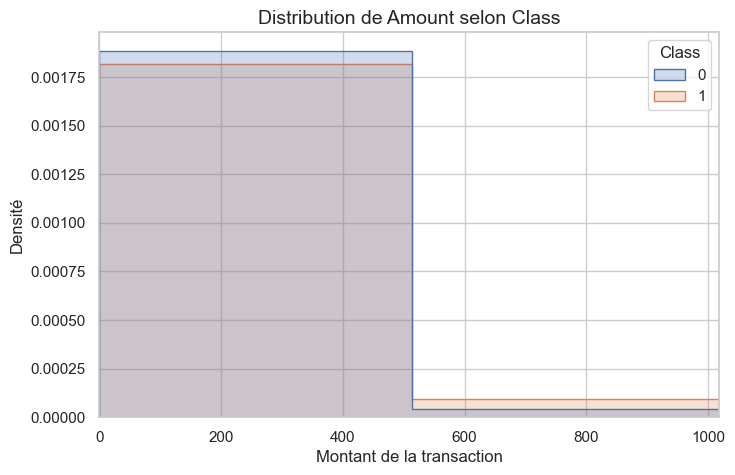

In [ ]:
# Distribution du montant selon la classe
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Amount", hue="Class", bins=50, kde=False, element="step", stat="density", common_norm=False)
plt.title("Distribution de Amount selon Class")
plt.xlabel("Montant de la transaction")
plt.ylabel("Densité")
plt.xlim(0, df["Amount"].quantile(0.99))
plt.show()

**Interprétation :** la distribution des montants permet de comparer les transactions normales et frauduleuses. On limite l'axe à 99% des montants pour éviter que quelques très grands montants écrasent la lecture du graphique.

C:\Users\YASSINE\AppData\Local\Temp\ipykernel_12788\1049963835.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Class", y="Amount", palette=["#4C78A8", "#E45756"])


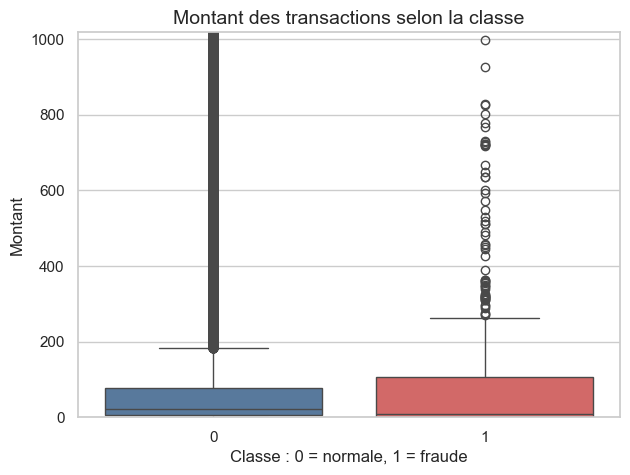

In [39]:
# Boxplot du montant selon la classe
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Class", y="Amount", palette=["#4C78A8", "#E45756"])
plt.title("Montant des transactions selon la classe")
plt.xlabel("Classe : 0 = normale, 1 = fraude")
plt.ylabel("Montant")
plt.ylim(0, df["Amount"].quantile(0.99))
plt.show()

**Interprétation :** ce boxplot aide à visualiser les différences de montant entre les classes. Les outliers existent, donc on limite l'affichage au 99e percentile pour garder une lecture claire.

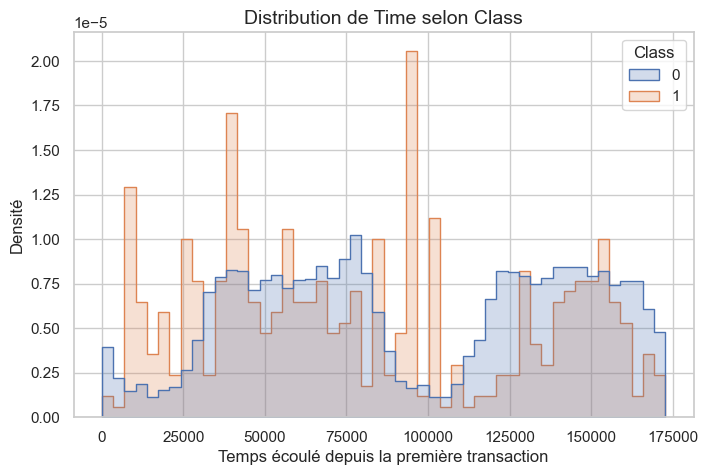

In [40]:
# Distribution de Time selon la classe
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Time", hue="Class", bins=50, element="step", stat="density", common_norm=False)
plt.title("Distribution de Time selon Class")
plt.xlabel("Temps écoulé depuis la première transaction")
plt.ylabel("Densité")
plt.show()

**Interprétation :** cette visualisation permet de voir si les fraudes apparaissent davantage à certains moments. La variable Time ne donne pas une date réelle, mais elle peut contenir une information utile pour les modèles.

In [41]:
# Corrélations simples avec la cible
correlations = df.corr(numeric_only=True)["Class"].sort_values(key=abs, ascending=False)
correlations.head(12)

Class    1.000000
V17     -0.326481
V14     -0.302544
V12     -0.260593
V10     -0.216883
V16     -0.196539
V3      -0.192961
V7      -0.187257
V11      0.154876
V4       0.133447
V18     -0.111485
V1      -0.101347
Name: Class, dtype: float64

**Interprétation :** les corrélations indiquent quelles variables sont le plus liées à la classe. Attention : une corrélation faible ne signifie pas forcément qu'une variable est inutile pour un modèle.

## 6. 06_data_quality_and_cleaning

On vérifie la qualité des données : valeurs manquantes, doublons et types de variables. On garde le nettoyage simple pour rester beginner-friendly.

In [42]:
# Vérification des valeurs manquantes
missing_values = df.isna().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [43]:
# Vérification des doublons
n_duplicates = df.duplicated().sum()
print("Nombre de lignes dupliquées :", n_duplicates)

# Pour ce projet simple, on supprime les doublons exacts si présents.
# Cela évite qu'une même transaction exacte influence plusieurs fois le modèle.
df_clean = df.drop_duplicates().copy()

print("Dimensions avant nettoyage :", df.shape)
print("Dimensions après nettoyage :", df_clean.shape)

Nombre de lignes dupliquées : 1081
Dimensions avant nettoyage : (284807, 31)
Dimensions après nettoyage : (283726, 31)


In [44]:
# Vérification finale après nettoyage
print("Valeurs manquantes restantes :", df_clean.isna().sum().sum())
print("Doublons restants :", df_clean.duplicated().sum())

Valeurs manquantes restantes : 0
Doublons restants : 0


**Interprétation :** cette étape permet de s'assurer que le dataset est exploitable. Les doublons exacts sont retirés pour éviter une répétition artificielle d'observations identiques.

## 7. 07_preprocessing

On prépare les données pour les modèles.

Règles importantes respectées :

- la cible est `Class` ;
- on sépare les données avant tout apprentissage du scaler ;
- on utilise `stratify=y` pour garder la même proportion de fraudes dans train et test ;
- on ne fait pas d'undersampling avant le split ;
- on standardise seulement `Amount` et `Time` avec `StandardScaler`.

In [45]:
# Séparation entre variables explicatives X et cible y
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

# Split train/test avec stratification pour conserver la rareté des fraudes
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Taille X_train :", X_train.shape)
print("Taille X_test :", X_test.shape)
print("Pourcentage de fraudes dans y_train :", y_train.mean() * 100)
print("Pourcentage de fraudes dans y_test :", y_test.mean() * 100)

Taille X_train : (226980, 30)
Taille X_test : (56746, 30)
Pourcentage de fraudes dans y_train : 0.16653449643140364
Pourcentage de fraudes dans y_test : 0.16741268107003138


In [ ]:
# Standardisation de Amount et Time
# Important : le scaler est appris uniquement sur X_train pour éviter la fuite de données.
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

columns_to_scale = ["Amount", "Time"]
X_train_scaled[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_test_scaled[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

X_train_scaled.head()
X_test_scaled.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
226238,1.045499,2.238954,-1.724499,-2.151484,-2.577803,0.993668,3.565492,-1.785957,0.860122,-1.264003,...,-0.323810,-0.149574,-0.049333,0.278442,0.684735,-0.219028,-0.159167,0.037920,-0.049932,-0.229434
134253,-0.298690,-1.315062,1.630783,0.597001,-0.038359,-0.404580,-0.965712,0.212249,0.735381,-1.267926,...,-0.067580,-0.238898,-0.946773,0.323904,0.515632,-0.713000,-0.266503,-0.017794,0.051058,-0.331197
186465,0.678397,1.908801,0.021184,-2.087997,0.129310,1.161468,0.605244,-0.022371,0.180296,0.283819,...,-0.210474,0.293609,1.095842,-0.044874,-1.689517,0.106098,0.007758,0.045164,-0.053068,-0.298809
149493,-0.074929,1.811257,0.316556,0.316751,3.880231,0.048454,1.020163,-0.734868,0.233651,0.681423,...,-0.228032,0.138869,0.700422,0.174064,0.702997,-0.212523,-0.010018,-0.017740,-0.038006,-0.289247
18461,-1.376728,1.358817,-1.120881,0.550266,-1.547659,-1.194950,0.275448,-1.201843,0.212889,-2.094285,...,-0.361686,-0.340972,-0.636442,0.252758,-0.344160,-0.064282,-0.439622,0.062524,0.013095,-0.261985


## 8. 08_modeling_or_clustering

On teste trois approches :

1. Logistic Regression avec poids équilibrés ;
2. Random Forest avec poids équilibrés ;
3. Isolation Forest comme méthode d'anomalie.

Les modèles supervisés utilisent `Class` pendant l'entraînement. Isolation Forest est une méthode d'anomalie : elle apprend surtout ce qui ressemble à un comportement normal.

In [47]:
# Modèle 1 : Logistic Regression
log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE
)

log_reg.fit(X_train_scaled, y_train)

# Probabilité d'appartenir à la classe fraude
proba_log_reg = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Exemple de probabilités prédites par Logistic Regression :")
print(proba_log_reg[:10])

Exemple de probabilités prédites par Logistic Regression :
[0.02174443 0.0200754  0.01030991 0.01586962 0.21952976 0.06095884
 0.02226741 0.03881125 0.08691862 0.00180457]


In [48]:
# Modèle 2 : Random Forest
random_forest = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_forest.fit(X_train_scaled, y_train)
proba_random_forest = random_forest.predict_proba(X_test_scaled)[:, 1]

print("Exemple de probabilités prédites par Random Forest :")
print(proba_random_forest[:10])

Exemple de probabilités prédites par Random Forest :
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [49]:
# Modèle 3 : Isolation Forest
# contamination indique la proportion attendue d'anomalies.
# Ici, on utilise la proportion de fraudes observée dans le train comme estimation simple.
contamination_rate = max(y_train.mean(), 0.001)

isolation_forest = IsolationForest(
    n_estimators=100,
    contamination=contamination_rate,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

isolation_forest.fit(X_train_scaled)

# decision_function donne un score plus élevé pour les points normaux.
# On inverse donc le signe pour obtenir un score plus élevé quand la transaction paraît suspecte.
scores_isolation = -isolation_forest.decision_function(X_test_scaled)

print("Exemple de scores d'anomalie par Isolation Forest :")
print(scores_isolation[:10])

Exemple de scores d'anomalie par Isolation Forest :
[-0.29646089 -0.2780761  -0.22209538 -0.27493643 -0.28186541 -0.30343085
 -0.26389627 -0.23901289 -0.25540638 -0.26953172]


## 9. 09_evaluation

On évalue les modèles sur le jeu de test uniquement.

Les métriques principales sont :

- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Matrice de confusion

On évite d'utiliser l'accuracy comme métrique principale car le dataset est très déséquilibré.

In [50]:
def evaluate_binary_model(y_true, scores, threshold=0.5, model_name="Modèle"):
    """Évalue un modèle à partir de scores ou probabilités de fraude."""
    y_pred = (scores >= threshold).astype(int)
    
    return {
        "Model": model_name,
        "Threshold": threshold,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores),
        "PR-AUC": average_precision_score(y_true, scores)
    }

# Isolation Forest ne produit pas une probabilité entre 0 et 1.
# Pour comparer avec un seuil simple, on transforme ses scores en rangs normalisés entre 0 et 1.
def normalize_scores(scores):
    min_score = np.min(scores)
    max_score = np.max(scores)
    return (scores - min_score) / (max_score - min_score)

scores_isolation_norm = normalize_scores(scores_isolation)

In [51]:
# Comparaison des modèles dans un tableau clair
results = []

results.append(evaluate_binary_model(y_test, proba_log_reg, threshold=0.5, model_name="Logistic Regression"))
results.append(evaluate_binary_model(y_test, proba_random_forest, threshold=0.5, model_name="Random Forest"))
results.append(evaluate_binary_model(y_test, scores_isolation_norm, threshold=0.5, model_name="Isolation Forest"))

results_df = pd.DataFrame(results)
results_df[["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]] = results_df[["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]].round(4)
results_df

,Model,Threshold,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.5,0.0564,0.8737,0.1060,0.9657,0.6738
1,Random Forest,0.5,0.9710,0.7053,0.8171,0.9246,0.7959
2,Isolation Forest,0.5,0.0628,0.5579,0.1129,0.9300,0.1060


**Interprétation :** ce tableau compare les modèles avec des métriques adaptées aux fraudes rares. Le recall indique combien de fraudes sont détectées, tandis que la precision indique combien d'alertes sont réellement des fraudes.

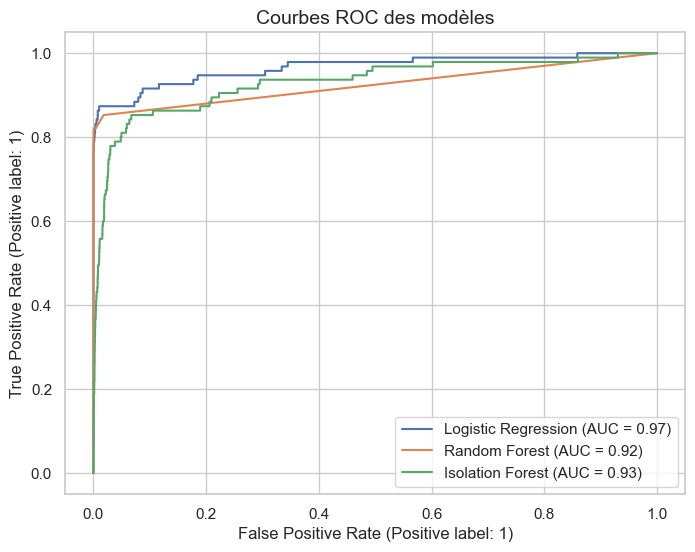

In [52]:
# Courbes ROC pour les trois modèles
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_predictions(y_test, proba_log_reg, name="Logistic Regression", ax=plt.gca())
RocCurveDisplay.from_predictions(y_test, proba_random_forest, name="Random Forest", ax=plt.gca())
RocCurveDisplay.from_predictions(y_test, scores_isolation_norm, name="Isolation Forest", ax=plt.gca())
plt.title("Courbes ROC des modèles")
plt.show()

**Interprétation :** la courbe ROC montre la capacité du modèle à séparer les classes. Plus la courbe est proche du coin supérieur gauche, meilleur est le modèle. Mais sur un dataset très déséquilibré, la courbe Precision-Recall est souvent plus parlante.

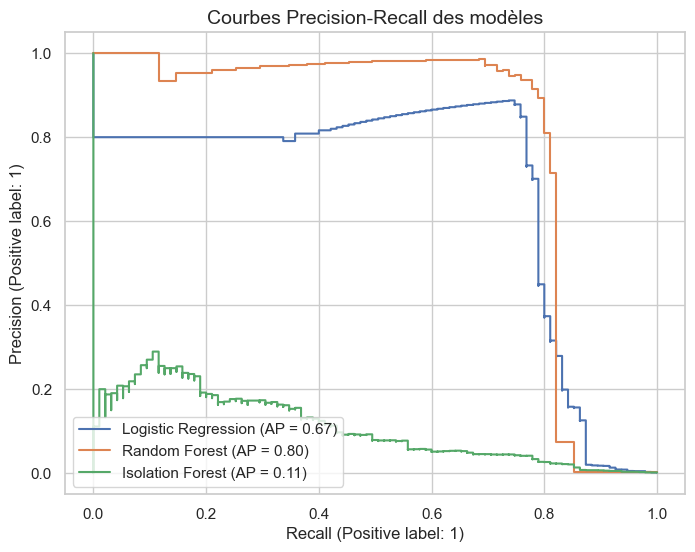

In [53]:
# Courbes Precision-Recall pour les trois modèles
plt.figure(figsize=(8, 6))
PrecisionRecallDisplay.from_predictions(y_test, proba_log_reg, name="Logistic Regression", ax=plt.gca())
PrecisionRecallDisplay.from_predictions(y_test, proba_random_forest, name="Random Forest", ax=plt.gca())
PrecisionRecallDisplay.from_predictions(y_test, scores_isolation_norm, name="Isolation Forest", ax=plt.gca())
plt.title("Courbes Precision-Recall des modèles")
plt.show()

**Interprétation :** la courbe Precision-Recall est très utile ici car la classe fraude est rare. Un bon modèle doit garder un recall élevé sans faire chuter trop fortement la precision.

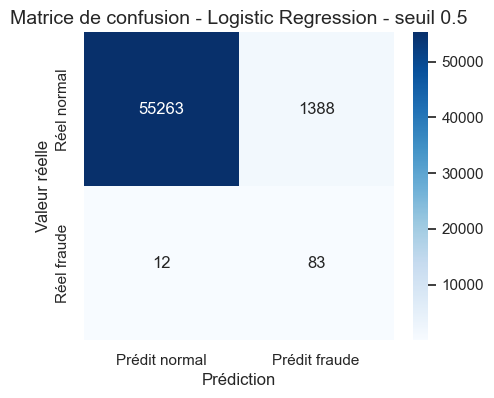

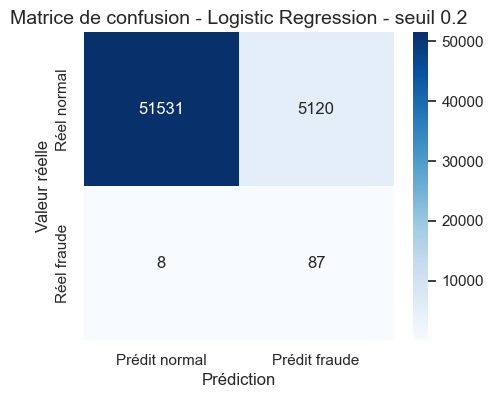

In [54]:
def plot_confusion_matrix_for_threshold(y_true, scores, threshold, title):
    """Affiche une matrice de confusion pour un seuil donné."""
    y_pred = (scores >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Prédit normal", "Prédit fraude"],
        yticklabels=["Réel normal", "Réel fraude"]
    )
    plt.title(title)
    plt.xlabel("Prédiction")
    plt.ylabel("Valeur réelle")
    plt.show()
    
    return cm

# On choisit Logistic Regression pour analyser clairement l'impact du seuil.
cm_05 = plot_confusion_matrix_for_threshold(
    y_test,
    proba_log_reg,
    threshold=0.5,
    title="Matrice de confusion - Logistic Regression - seuil 0.5"
)

cm_02 = plot_confusion_matrix_for_threshold(
    y_test,
    proba_log_reg,
    threshold=0.2,
    title="Matrice de confusion - Logistic Regression - seuil 0.2"
)

**Interprétation :** avec un seuil plus bas, le modèle classe plus facilement une transaction comme fraude. Cela peut réduire les faux négatifs, mais cela augmente souvent les faux positifs.

In [55]:
# Comparaison détaillée entre deux seuils pour Logistic Regression
threshold_results = []
for threshold in [0.5, 0.2]:
    threshold_results.append(evaluate_binary_model(
        y_test,
        proba_log_reg,
        threshold=threshold,
        model_name="Logistic Regression"
    ))

threshold_results_df = pd.DataFrame(threshold_results)
threshold_results_df[["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]] = threshold_results_df[["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]].round(4)
threshold_results_df

,Model,Threshold,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.5,0.0564,0.8737,0.1060,0.9657,0.6738
1,Logistic Regression,0.2,0.0167,0.9158,0.0328,0.9657,0.6738


In [56]:
# Rapport de classification pour les deux seuils
for threshold in [0.5, 0.2]:
    y_pred_threshold = (proba_log_reg >= threshold).astype(int)
    print("=" * 70)
    print(f"Logistic Regression avec seuil {threshold}")
    print(classification_report(y_test, y_pred_threshold, target_names=["Normal", "Fraude"], zero_division=0))

Logistic Regression avec seuil 0.5
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     56651
      Fraude       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746

Logistic Regression avec seuil 0.2
              precision    recall  f1-score   support

      Normal       1.00      0.91      0.95     56651
      Fraude       0.02      0.92      0.03        95

    accuracy                           0.91     56746
   macro avg       0.51      0.91      0.49     56746
weighted avg       1.00      0.91      0.95     56746



**Interprétation métier du seuil :**

- Un seuil de **0.5** est plus strict : il faut une probabilité élevée pour déclencher une alerte fraude.
- Un seuil de **0.2** est plus sensible : il détecte souvent plus de fraudes, mais il peut bloquer plus de transactions normales.

Dans la fraude bancaire, les faux négatifs sont dangereux car ils correspondent à des fraudes non détectées. Cela peut causer une perte financière directe et une mauvaise expérience pour le client victime.

Les faux positifs sont aussi gênants : une transaction normale peut être bloquée, ce qui peut frustrer un client. Le bon seuil dépend donc du coût métier des erreurs.

In [57]:
# Exemple simple du coût métier des erreurs pour le seuil 0.5 et 0.2
for threshold in [0.5, 0.2]:
    y_pred_threshold = (proba_log_reg >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold).ravel()
    
    print(f"Seuil {threshold}")
    print(f"Vrais positifs  (fraudes détectées)       : {tp}")
    print(f"Faux négatifs   (fraudes non détectées)   : {fn}")
    print(f"Faux positifs   (transactions bloquées)   : {fp}")
    print(f"Vrais négatifs  (transactions normales OK): {tn}")
    print("-")

Seuil 0.5
Vrais positifs  (fraudes détectées)       : 83
Faux négatifs   (fraudes non détectées)   : 12
Faux positifs   (transactions bloquées)   : 1388
Vrais négatifs  (transactions normales OK): 55263
-
Seuil 0.2
Vrais positifs  (fraudes détectées)       : 87
Faux négatifs   (fraudes non détectées)   : 8
Faux positifs   (transactions bloquées)   : 5120
Vrais négatifs  (transactions normales OK): 51531
-


**Interprétation :** un faux négatif signifie qu'une fraude passe sans alerte. Un faux positif signifie qu'une transaction normale est bloquée ou vérifiée inutilement. En pratique, la banque doit choisir un seuil selon sa tolérance au risque et sa capacité à traiter les alertes.

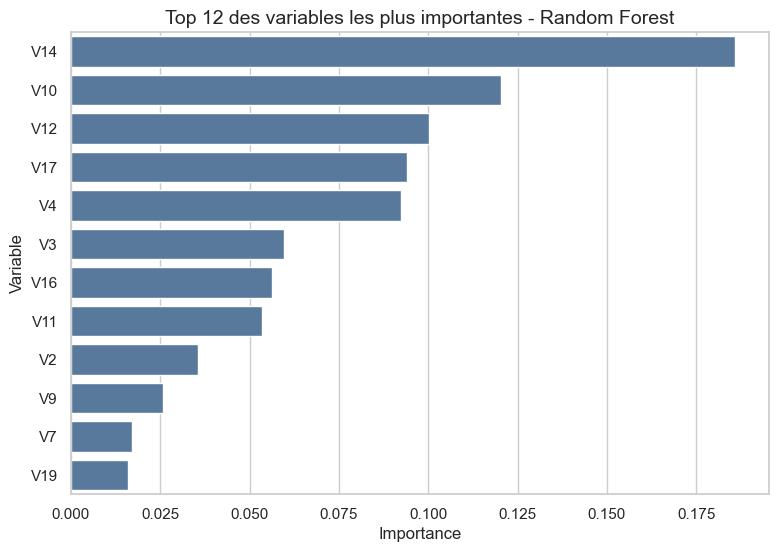

,feature,importance
14,V14,0.185906
10,V10,0.120391
12,V12,0.100258
17,V17,0.094048
4,V4,0.092252
3,V3,0.059660
16,V16,0.056156
11,V11,0.053584
2,V2,0.035558
9,V9,0.025836


In [58]:
# Importance des variables pour Random Forest
feature_importances = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "importance": random_forest.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=feature_importances.head(12), x="importance", y="feature", color="#4C78A8")
plt.title("Top 12 des variables les plus importantes - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.show()

feature_importances.head(12)

**Interprétation :** ce graphique donne une idée des variables les plus utilisées par Random Forest. Il faut rester prudent : les variables V1 à V28 sont anonymisées, donc leur interprétation métier directe est limitée.

## 10. 10_interpretation_and_limits

### Pourquoi l'accuracy est trompeuse ?

Le dataset contient très peu de fraudes. Si seulement environ 0,17% des transactions sont frauduleuses, un modèle qui prédit toujours "transaction normale" peut obtenir une accuracy proche de 99,8%, tout en détectant **zéro fraude**.

Dans ce projet, il est donc plus utile de regarder le recall, la precision, le F1-score et surtout la PR-AUC.

### Analyse métier simple du coût des erreurs

- **Faux négatif** : une fraude n'est pas détectée. C'est dangereux car la banque ou le client peut perdre de l'argent.
- **Faux positif** : une transaction normale est bloquée. C'est moins grave qu'une fraude non détectée, mais cela peut gêner le client.

### Conclusion finale

Le meilleur modèle dépend de l'objectif métier :

- si l'objectif principal est de détecter un maximum de fraudes, il faut privilégier le **recall** ;
- si l'objectif est de limiter les fausses alertes, il faut privilégier la **precision** ;
- pour un compromis, on regarde le **F1-score** ;
- pour un dataset très déséquilibré, la **PR-AUC** est une métrique très importante.

Dans une présentation orale, on peut expliquer que baisser le seuil de décision, par exemple de 0.5 à 0.2, rend le modèle plus sensible aux fraudes, mais augmente le nombre de transactions normales signalées comme suspectes.

### Limites du projet

- Les variables V1 à V28 sont anonymisées, donc l'interprétation métier est limitée.
- Le dataset est ancien et ne représente pas forcément les fraudes actuelles.
- Les modèles sont simples et les hyperparamètres ne sont pas optimisés en profondeur.
- Le coût réel des erreurs n'est pas chiffré précisément.

### Améliorations possibles

- Optimiser les hyperparamètres avec validation croisée.
- Tester d'autres modèles comme Gradient Boosting ou XGBoost.
- Ajuster le seuil selon un coût métier réel.
- Ajouter une analyse temporelle plus détaillée.
- Utiliser des méthodes de rééquilibrage uniquement après le split, et uniquement sur le jeu d'entraînement.